In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset load karne ke liye read_excel ya read_csv use karein
# (Kyunki file ka type XLS dikha raha hai, isliye pd.read_excel('churn.csv') likhein)
df = pd.read_excel('churn.csv')

# Pehle 5 rows check karein
print(df.head())

ValueError: Excel file format cannot be determined, you must specify an engine manually.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ab hum pd.read_csv ka use karenge kyunki file asal mein CSV hai
df = pd.read_csv('churn.csv')

# Pehle 5 rows check karein
print(df.head())

   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [3]:
# 1. 'TotalCharges' ko numeric mein convert karein aur missing values fill karein
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)

# 2. 'customerID' prediction ke kaam nahi aata, isliye drop kar dein
if 'customerID' in df.columns:
    df.drop('customerID', axis=1, inplace=True)

# 3. Target variable 'Churn' ko 0 aur 1 mein badlein (Yes -> 1, No -> 0)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

# 4. Baaki categorical columns ko One-Hot Encoding se numbers mein convert karein
df = pd.get_dummies(df, drop_first=True)

print("Data Cleaning & Encoding Successfully Completed!")
print("New Shape of Dataset:", df.shape)

Data Cleaning & Encoding Successfully Completed!
New Shape of Dataset: (7043, 31)


C:\Users\goura\AppData\Local\Temp\ipykernel_31820\468814926.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['TotalCharges'].fillna(df['TotalCharges'].median(), inplace=True)


In [6]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, accuracy_score

# 1. Features (X) aur Target (y) ko alag karein
X = df.drop('Churn', axis=1)
y = df['Churn']

# 2. Train aur Test split karein (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Missing values ko handle karein (NaN ko 0 banayein)
X_train = X_train.fillna(0)
X_test = X_test.fillna(0)

# 4. SMOTE ka use karke Class Imbalance theek karein
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print("Before SMOTE, counts of label '1':", sum(y_train == 1))
print("After SMOTE, counts of label '1':", sum(y_train_resampled == 1))

# 5. Teeno Models ko train aur evaluate karein
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(random_state=42, eval_metric='logloss')
}

for name, model in models.items():
    print(f"\n--- {name} Results ---")
    model.fit(X_train_resampled, y_train_resampled)
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("ROC-AUC Score:", roc_auc_score(y_test, y_prob))
    print("Classification Report:\n", classification_report(y_test, y_pred))

Before SMOTE, counts of label '1': 1495
After SMOTE, counts of label '1': 4139

--- Logistic Regression Results ---


C:\Users\goura\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Accuracy: 0.7544357700496807
ROC-AUC Score: 0.8093983311374616
Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.80      0.83      1035
           1       0.53      0.63      0.57       374

    accuracy                           0.75      1409
   macro avg       0.69      0.71      0.70      1409
weighted avg       0.77      0.75      0.76      1409


--- Random Forest Results ---
Accuracy: 0.7714691270404542
ROC-AUC Score: 0.8192913792658039
Classification Report:
               precision    recall  f1-score   support

           0       0.85      0.84      0.84      1035
           1       0.57      0.58      0.58       374

    accuracy                           0.77      1409
   macro avg       0.71      0.71      0.71      1409
weighted avg       0.77      0.77      0.77      1409


--- XGBoost Results ---
Accuracy: 0.765791341376863
ROC-AUC Score: 0.812103128471415
Classification Report:
               precision    reca

--- Top 5 Churn Drivers (Features) ---
                           Feature  Importance
28  PaymentMethod_Electronic check    0.281441
10     InternetService_Fiber optic    0.085913
25               Contract_Two year    0.079191
11              InternetService_No    0.056382
26            PaperlessBilling_Yes    0.052560


C:\Users\goura\AppData\Local\Temp\ipykernel_31820\3869706207.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance.head(5), palette='viridis')


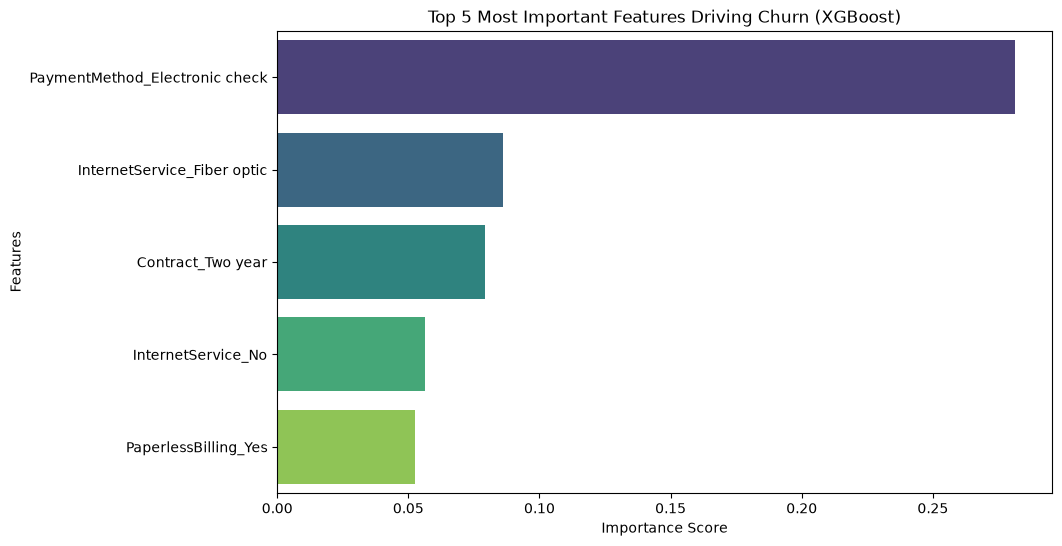


--- Customer Risk Segmentation Count ---
Risk_Group
Low Risk       938
High Risk      239
Medium Risk    232
Name: count, dtype: int64


In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. XGBoost model se Top 5 Features nikaalein
# (Kyunki upar wale loop mein XGBoost train ho chuka hai, hum uske 'feature_importances_' use kar sakte hain)
xgb_model = models["XGBoost"]

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': xgb_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("--- Top 5 Churn Drivers (Features) ---")
print(feature_importance.head(5))

# 2. Feature Importance Plot banayein
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance.head(5), palette='viridis')
plt.title('Top 5 Most Important Features Driving Churn (XGBoost)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.show()

# 3. Customer Risk Scoring (Probability Scores)
# Har customer ke liye churn probability calculate karein
churn_probabilities = xgb_model.predict_proba(X_test)[:, 1]

# Risk Segmentation DataFrame banayein
risk_df = pd.DataFrame({
    'Actual_Churn': y_test.values,
    'Churn_Probability': churn_probabilities
})

# Risk Groups Assign Karein
# > 0.7 -> High Risk, 0.4 - 0.7 -> Medium Risk, < 0.4 -> Low Risk
def assign_risk(prob):
    if prob > 0.7:
        return 'High Risk'
    elif prob >= 0.4:
        return 'Medium Risk'
    else:
        return 'Low Risk'

risk_df['Risk_Group'] = risk_df['Churn_Probability'].apply(assign_risk)

print("\n--- Customer Risk Segmentation Count ---")
print(risk_df['Risk_Group'].value_counts())